In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
from tqdm import tqdm
from pathlib import Path

pd.options.display.max_columns = None

In [2]:
# Read disentangled variant files
m = pd.read_csv('../../../datasets/genomics/01_variant_calling/results/raw_no_bg.tsv', sep = '\t', keep_default_na = False)

# Read reference genome
#with open('../../../datasets/genomics/reference_genome/U00096_raw.txt') as f:
#    genome = f.read().replace('\n', '')

In [3]:
# Read reference genome
genome = dict()

with open('../../../datasets/genomics/reference_genome/U00096_raw.txt') as f:
    #next(f)
    genome['U00096'] = f.read().replace('\n', '')
    
with open('../../../datasets/genomics/reference_genome/JX871397_raw.txt') as f:
    #next(f)
    genome['JX871397'] = f.read().replace('\n', '')

In [4]:
def find_repeat_start(chrom, pos):
    # For repeat number change mutations, find where the repeat starts
    #pos -= 1 # the repeat's base is the one before pos
    letter = genome[chrom][pos]
    
    while genome[chrom][pos - 1] == letter: # check the base before
        pos -= 1
        
    return pos

def find_repeat_end(chrom, pos):
    # Find the length of a repeat on the genome, starting at pos
    letter = genome[chrom][pos]
    p = pos + 1
    
    while genome[chrom][p] == letter:
        p += 1
        
    return p

# Fix broken repeats

In [5]:
r = m.copy()

# Important: r must be sorted by pop, gen, pos, -type, so for a given pop/gen/pos, the SNPs and REPs will be *before* the INS
r.sort_values(['pop', 'gen', 'chrom', 'pos', 'type'], ascending = [True, True, True, True, False], inplace = True)
r.reset_index(drop = True, inplace = True)

# Find all insertions
all_ins = r[r['type'] == 'INS'].rename_axis('row').reset_index()

In [6]:
from types import SimpleNamespace

freq_thr = 0.25 # if the splitter is much rarer than the INS

# Make a copy of r to modify
new_r = r.copy()
new_r['split'] = 0

#for ins in all_ins[(all_ins.pos == 3681792) & (all_ins['pop'] == 'G')].reset_index(drop = True).to_dict(orient = 'records'):
for ins in all_ins.to_dict(orient="records"):
    
    i = SimpleNamespace(**ins)
    
    # Find INS with only one kind of nucleotide
    if len(set(i.alt)) != 1:
        continue
                
    nt = i.alt[0] # the nucleotide we are talking about
    stretch_start = find_repeat_start(i.chrom, i.pos - 1) + 1
    stretch_end = find_repeat_end(i.chrom, i.pos - 1) + 1
    
    assert r.loc[i.row]['pos'] == i.pos # check that there's no index error
    
    ##################
    # Forward search #
    ##################
               
    # Due to reverse-sorting by type, the mutations we are looking for are all before the INS
    row = i.row - 1
    hit = 0
    
    # Look backwards in r until the beginning of the stretch
    while (r.loc[row]['pos'] >= stretch_start) and (r.loc[row]['name'] == i.name) and (r.loc[row]['chrom'] == i.chrom):
                
        # Search forward
        if stretch_end == i.pos + 1 and any([
            (r.loc[row]['pos'] == i.pos) and (r.loc[row]['type'] == 'SNP') and (r.loc[row]['alt'] == nt), # SNP at pos that goes to nt
            (r.loc[row]['pos_end'] == i.pos + 1) and (r.loc[row]['type'] == 'REP') and (r.loc[row]['delta'] == -1) # Δ-1 that finishes at pos
            ]):
                          
            # Is there a potential REP of nt at pos+1?
            if genome[i.chrom][i.pos] == nt:

                if hit: print(f'{i.name}: multiple hits for the same INS ({i.row}) at {i.pos}!\n') # Check that it's the first hit
                
                hit = int(row)
                
                if r.loc[row].freq < freq_thr and i.freq > r.loc[row].freq + freq_thr:
                    print('The splitter frequency is too low! (forward)')
                    print('Ins:', i.row, ' - ', i.name, i.pos, f'{i.ref}>{i.alt}', i.locus, i.freq)
                    print('Hit (fw):', hit, ' - ', list(r.loc[row][['name', 'pos', 'ref', 'alt', 'locus', 'freq']]), 'next: ', genome[i.chrom][i.pos - 3])
                    print()
                
                else:
                    print('Ins:', i.row, ' - ', i.name, i.pos, f'{i.ref}>{i.alt}', i.locus, i.freq)
                    print('Hit (fw):', hit, ' - ', list(r.loc[row][['name', 'pos', 'ref', 'alt', 'locus', 'freq']]), 'next: ', genome[i.chrom][i.pos - 3])
                    print()
                                        
                    # If something was found, modify the pos of the INS to match the REP region where it belongs
                    new_pos_start = i.pos + 1
                    new_pos_end = find_repeat_end(i.chrom, i.pos) + 1
                    
                    new_r.loc[i.row, 'pos'] = new_pos_start
                    new_r.loc[i.row, 'pos_end'] = new_pos_end
                    new_r.loc[i.row, 'rep_len'] = new_pos_end - new_pos_start
                    new_r.loc[i.row, 'rep_nt'] = nt
                    
                    new_r.loc[i.row, 'type'] = 'REP'
                    new_r.loc[i.row, 'split'] = 2 # flag it

                    # Also label the SNP/DEL that split the stretch
                    new_r.loc[row, 'split'] = 1 # flag it
        
        # Search backward
        if any([
            (r.loc[row]['pos'] == i.pos - 1) and (r.loc[row]['type'] == 'SNP') and (r.loc[row]['alt'] == nt),
            (r.loc[row]['pos'] == i.pos - 1) and (r.loc[row]['type'] == 'REP') and (r.loc[row]['delta'] == -1) and (r.loc[row]['rep_len'] == 1)
            ]):
            
            if genome[i.chrom][i.pos - 3] == nt:
                
                if hit: print(f'{i.name}: multiple hits for the same INS ({i.row}) at {i.pos}!\n') # Check that it's the first hit
                
                hit = int(row)
                
                if r.loc[row].freq < freq_thr and i.freq > r.loc[row].freq + freq_thr:
                    print('The splitter frequency is too low! (backward)')
                    print('Ins:', i.row, ' - ', i.name, i.pos, f'{i.ref}>{i.alt}', i.locus, i.freq)
                    print('Hit (rev):', hit, ' - ', list(r.loc[row][['name', 'pos', 'ref', 'alt', 'locus', 'freq']]), 'next: ', genome[i.chrom][i.pos - 3])
                    print()
                
                else:
                    print('Ins:', i.row, ' - ', i.name, i.pos, f'{i.ref}>{i.alt}', i.locus, i.freq)
                    print('Hit (rev):', hit, ' - ', list(r.loc[row][['name', 'pos', 'ref', 'alt', 'locus', 'freq']]), 'next: ', genome[i.chrom][i.pos - 3])
                    print()
                    
                    # If something was found, modify the pos of the INS to match the REP region where it belongs
                    new_pos_start = find_repeat_start(i.chrom, i.pos - 3) + 1
                    new_pos_end = find_repeat_end(i.chrom, i.pos - 3) + 1
                    
                    new_r.loc[i.row, 'pos'] = new_pos_start
                    new_r.loc[i.row, 'pos_end'] = new_pos_end
                    new_r.loc[i.row, 'rep_len'] = new_pos_end - new_pos_start
                    new_r.loc[i.row, 'rep_nt'] = nt
                    
                    new_r.loc[i.row, 'type'] = 'REP'
                    new_r.loc[i.row, 'split'] = 4 # flag it

                    # Also label the SNP/DEL that split the stretch
                    new_r.loc[row, 'split'] = 3 # flag it
        
        row -= 1
    
        # Reverse: find either a SNP at pos-1, a REP at pos-1

Ins: 78676  -  EE20 311482 >T TTTTTTTC..CCGATGAGT 0.011
Hit (rev): 78675  -  ['EE20', 311481, 'C', 'T', 'TTTTTTTT.C.CCGATGAGT', 0.6186] next:  T

Ins: 80723  -  EE23 311482 >T TTTTTTTC..CCGATGAGT 0.0419
Hit (rev): 80721  -  ['EE23', 311481, 'C', 'T', 'TTTTTTTT.C.CCGATGAGT', 1.0] next:  T

Ins: 81395  -  EE24 311482 >T TTTTTTTC..CCGATGAGT 0.0365
Hit (rev): 81393  -  ['EE24', 311481, 'C', 'T', 'TTTTTTTT.C.CCGATGAGT', 0.9893] next:  T

Ins: 94001  -  EF13 1097138 >CCC GCTTCTCA..TCCCCCCGG 0.6734
Hit (fw): 94000  -  ['EF13', 1097138, 'T', '', 'GCTTCTCA.T.CCCCCCGGT', 0.529] next:  C

Ins: 96668  -  EF14 3379259 >CCCCC TTCTCGTT..TCCCCCCCG 0.1324
Hit (fw): 96667  -  ['EF14', 3379259, 'T', 'C', 'TTCTCGTT.T.CCCCCCCGC', 0.0482] next:  T

Ins: 97967  -  EF15 2883092 >CCC TTACGATA..TCCCCCCAT 0.8334
Hit (fw): 97966  -  ['EF15', 2883092, 'T', '', 'TTACGATA.T.CCCCCCATA', 0.8268] next:  T

Ins: 100367  -  EF17 3379259 >CCC TTCTCGTT..TCCCCCCCG 0.1797
Hit (fw): 100366  -  ['EF17', 3379259, 'T', 'C', 'TTC

Ins: 144484  -  EH14 638788 >G AAGGGGGC..CATTTTACT 0.0332
Hit (rev): 144483  -  ['EH14', 638787, 'C', 'G', 'AAAGGGGG.C.CATTTTACT', 1.0] next:  G

Ins: 148875  -  EH16 638788 >G AAGGGGGC..CATTTTACT 0.02
Hit (rev): 148874  -  ['EH16', 638787, 'C', 'G', 'AAAGGGGG.C.CATTTTACT', 1.0] next:  G

Ins: 151736  -  EH17 1093360 >G TGGGGGGC..CGATAGTTG 0.0362
Hit (fw): 151735  -  ['EH17', 1093359, 'C', '', 'TTGGGGGG.CC.GATAGTTGC', 0.3551] next:  G

EH17: multiple hits for the same INS (151736) at 1093360!

Ins: 151736  -  EH17 1093360 >G TGGGGGGC..CGATAGTTG 0.0362
Hit (fw): 151734  -  ['EH17', 1093359, 'C', '', 'TTGGGGGG.CC.GATAGTTGC', 0.3938] next:  G

Ins: 151929  -  EH17 1594248 >CCC AAGCAATT..TCCCCCCCC 0.7572
Hit (fw): 151928  -  ['EH17', 1594246, 'T', '', 'GAAAGCAA.TTT.CCCCCCCCA', 0.5886] next:  T

Ins: 153684  -  EH18 1594248 >CCC AAGCAATT..TCCCCCCCC 0.5638
Hit (fw): 153683  -  ['EH18', 1594246, 'T', '', 'GAAAGCAA.TTT.CCCCCCCCA', 0.5458] next:  T

Ins: 155767  -  EH19 1594248 >CCCC AAGCAATT..

# Unify the INS+DEL and SNPs

Sometimes a SNP in one timepoint will register as a deletion (ending at pos) + an insertion (at pos+1) at another timepoint, breaking the continuity.

* Label the deletions with the frequency of the associated insertion
* Label the insertions with the frequency of the associated deletion, as a negative number

In [7]:
import time

mci = new_r.copy()

# Flag SNPs that might be involved in this
mci['next_nt'] = mci.apply(lambda x: genome[x.chrom][x.pos], axis = 1)
mci['sus_snp'] = (mci['type'] == 'SNP') & (mci.alt == mci.next_nt)

# Flag REPs that might be associated with such SNPs
mci['sus_del'] = mci.groupby(['pop', 'pos_end']).sus_snp.transform('any') & (mci.delta == -1)

mci.sort_values(['pop', 'gen', 'pos', 'type'], inplace = True)
mci.reset_index(drop = True, inplace = True)

In [8]:
all_sus = mci[mci.sus_del].rename_axis('row').sort_values(['pop', 'gen', 'pos']).reset_index()

In [9]:
freq_delta_thr = 0.2 # maximum difference in freq to consider two variants are twins

from types import SimpleNamespace

# Make a copy of mci to modify
new_mci = mci.copy()
new_mci['twin_freq'] = 0

#for snp in all_snps[(all_snps.pos == 1594248)].reset_index(drop = True).to_dict(orient = 'records'):
#for sus in all_sus[00:1500].to_dict(orient="records"):
for sus in all_sus.to_dict(orient="records"):
    
    i = SimpleNamespace(**sus)
    assert mci.loc[i.row]['pos'] == i.pos # check that there's no index error
        
    ##################
    # Forward search #
    ##################
    
    row = i.row + 1
    twin_freq = 0 # will be the freq of the most frequent twin
    twin_row = 0
    
    # Look for an insertion equivalent to the new base of an SNP in the same place
    # i.e., a REP whose pos is equal to the currently suspected REP's pos_end
    
    # seek to pos == pos_end
    while (mci.loc[row]['pos'] < i.pos_end) and (mci.loc[row]['name'] == i.name):
        
        #print(mci.loc[row]['pos'], mci.loc[row]['ref'], mci.loc[row]['alt'], mci.loc[row]['type'])
        row += 1
    
    # look for a REP insertion at pos_end
    while (mci.loc[row]['pos'] == i.pos_end) and (mci.loc[row]['name'] == i.name):
        
        if (mci.loc[row]['type'] == 'REP') and (mci.loc[row]['delta'] > 0):
            
            if mci.loc[row]['freq'] >= twin_freq:
                twin_freq = mci.loc[row]['freq']
                twin_row = row
            
        row += 1
        
    # Most frequent twin REP
    if twin_row:
        twin = mci.loc[twin_row]
        assert twin['freq'] == twin_freq
        
        # Check there's not a big freq difference
        if abs(i.freq - twin_freq) > freq_delta_thr:
            print(f'Warning: large freq difference for {i.pos}')
        
        # Flag the REP with the frequency of its twin
        new_mci.loc[i.row, 'twin_freq'] = twin_freq
        
        # Flag the twin with the frequency of its REP (in negative)
        new_mci.loc[twin_row, 'twin_freq'] = -i.freq
        
        print(f'{i.pos}\t{i.ref}\t{i.alt}\t{i.type}\t{i.freq}\t{i.locus}')
        print(f"{twin['pos']}\t{twin['ref']}\t{twin['alt']}\t{twin['type']}\t{twin['freq']}\t{i.name}")
        print()

1097138	T		REP	0.529	GCTTCTCA.T.CCCCCCGGT
1097139		CCC	REP	0.6734	EF13

3379257	T		REP	0.0142	TTTTCTCG.TTT.CCCCCCCGC
3379260		CCC	REP	0.7026	EF13

2883092	T		REP	0.8268	TTACGATA.T.CCCCCCATA
2883093		CCC	REP	0.8334	EF15

3379257	T		REP	0.0327	TTTTCTCG.TTT.CCCCCCCGC
3379260		C	REP	0.5048	EF15

1097138	T		REP	0.6659	GCTTCTCA.T.CCCCCCGGT
1097139		CCC	REP	0.8326	EG15

3379257	T		REP	0.0326	TTTTCTCG.TTT.CCCCCCCGC
3379260		CCC	REP	0.9027	EG15

1097138	T		REP	0.8701	GCTTCTCA.T.CCCCCCGGT
1097139		CCC	REP	0.9269	EG16

1594246	T		REP	0.935	GAAAGCAA.TTT.CCCCCCCCA
1594249		CCC	REP	0.9726	EG16

1594246	T		REP	0.9334	GAAAGCAA.TTT.CCCCCCCCA
1594249		CCC	REP	0.987	EG17

1594246	T		REP	0.8776	GAAAGCAA.TTT.CCCCCCCCA
1594249		CCC	REP	0.9391	EG18

1097138	T		REP	0.7774	GCTTCTCA.T.CCCCCCGGT
1097139		CCC	REP	0.8846	EG19

1594246	T		REP	0.8824	GAAAGCAA.TTT.CCCCCCCCA
1594249		CCC	REP	0.9261	EG19

1594246	T		REP	0.9023	GAAAGCAA.TTT.CCCCCCCCA
1594249		CCC	REP	0.9714	EG21

1594246	T		REP	0.8127	GAAAGCAA.TTT.CCCCC

/var/folders/s0/zd168x1d7bx_j31djdll88jc0000gn/T/ipykernel_80455/3011213762.py:54: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0.6734' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  new_mci.loc[i.row, 'twin_freq'] = twin_freq


Then, we identify the SNPs that are broken into del+ins in some generations, and break them into del+ins for consistency.

In [10]:
# Label the rows to be broken apart
new_mci['to_break'] = (new_mci.groupby(['pop', 'pos_end']).twin_freq.transform('max') > 0) & (new_mci.sus_snp)

### Turn a copy of SNPs into insertions at pos+1

In [11]:
# Copy them and turn them into insertions
prosthesis = new_mci[new_mci.to_break].reset_index(drop = True)

prosthesis['pos'] = prosthesis['pos'] + 1
#prosthesis['pos_end'] = (prosthesis.pos - 1).apply(find_repeat_end) + 1
prosthesis['pos_end'] = prosthesis.apply(lambda x: find_repeat_end(x.chrom, x.pos - 1), axis = 1) + 1
prosthesis['rep_len'] = prosthesis.pos_end - prosthesis.pos
prosthesis['rep_nt'] = prosthesis.alt

prosthesis['type'] = 'REP'
prosthesis['ref'] = ''
prosthesis['delta'] = 1

prosthesis[['name', 'pos', 'pos_end', 'ref', 'alt', 'freq', 'rep_len', 'rep_nt', 'type', 'delta', 'locus']]

,name,pos,pos_end,ref,alt,freq,rep_len,rep_nt,type,delta,locus
0,EF08,3379260,3379267,,C,0.0139,7,C,REP,1,TTCTCGTT.T.CCCCCCCGC
1,EF09,2883093,2883099,,C,0.0298,6,C,REP,1,TTACGATA.T.CCCCCCATA
2,EF10,1097139,1097145,,C,0.0881,6,C,REP,1,GCTTCTCA.T.CCCCCCGGT
3,EF10,2883093,2883099,,C,0.3401,6,C,REP,1,TTACGATA.T.CCCCCCATA
4,EF11,1097139,1097145,,C,0.3011,6,C,REP,1,GCTTCTCA.T.CCCCCCGGT
5,EF11,2883093,2883099,,C,0.5550,6,C,REP,1,TTACGATA.T.CCCCCCATA
6,EF12,1097139,1097145,,C,0.3808,6,C,REP,1,GCTTCTCA.T.CCCCCCGGT
7,EF12,2883093,2883099,,C,0.6566,6,C,REP,1,TTACGATA.T.CCCCCCATA
8,EF13,2883093,2883099,,C,1.0000,6,C,REP,1,TTACGATA.T.CCCCCCATA
9,EF14,1097139,1097145,,C,0.6664,6,C,REP,1,GCTTCTCA.T.CCCCCCGGT


### Turn the SNPs into deletions

In [12]:
new_new_mci = new_mci.copy()

# Adjust pos if needed
#new_new_mci['pos'] = np.where(new_new_mci.to_break, (new_new_mci.pos - 1).apply(find_repeat_start) + 1, new_new_mci.pos)
new_new_mci['pos'] = np.where(new_new_mci.to_break, new_new_mci.apply(lambda x: find_repeat_start(x.chrom, x.pos - 1), axis = 1) + 1
, new_new_mci.pos)
new_new_mci['rep_len'] = np.where(new_new_mci.to_break, new_new_mci.pos_end - new_new_mci.pos, new_new_mci.rep_len)
new_new_mci['rep_nt'] = np.where(new_new_mci.to_break, new_new_mci.ref, new_new_mci.rep_nt)

new_new_mci.loc[(new_new_mci.to_break), 'type'] = 'REP'
new_new_mci.loc[(new_new_mci.to_break), 'alt'] = ''
new_new_mci.loc[(new_new_mci.to_break), 'delta'] = -1

In [13]:
m_cont = pd.concat([new_new_mci, prosthesis])
m_cont.sort_values(['pop', 'pos', 'gen', 'type'], inplace = True)
m_cont.reset_index(drop = True, inplace = True)
#m_cont.drop(columns = ['next_nt', 'sus_snp', 'sus_del', 'twin_freq'], inplace = True)

In [14]:
m_cont.drop(columns = ['split', 'next_nt', 'sus_snp', 'sus_del', 'twin_freq', 'to_break'], inplace = True)

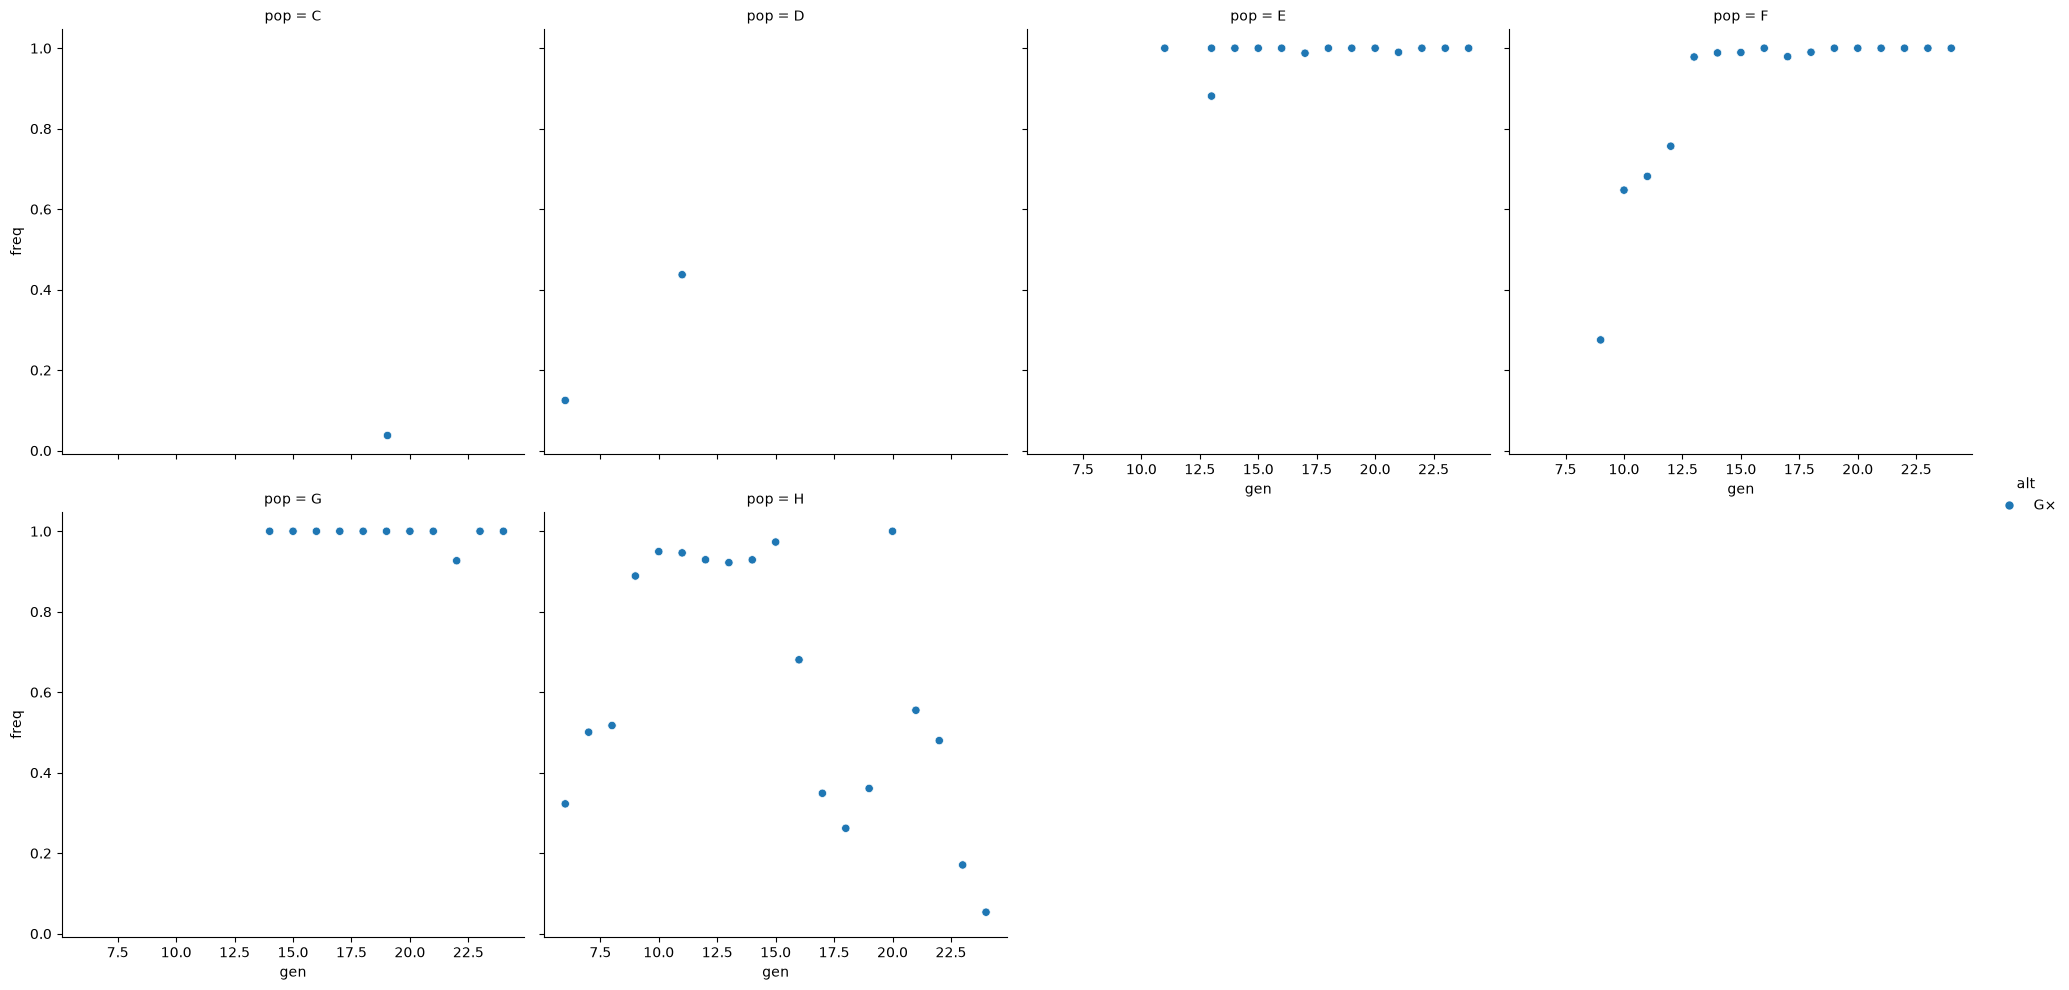

In [15]:
m_collapsed = m_cont.copy()
#m_collapsed = new_r.copy()

# Backup old values
m_collapsed['back_ref'] = m_collapsed['ref']
m_collapsed['back_alt'] = m_collapsed['alt']
m_collapsed['back_delta'] = m_collapsed['delta']

m_collapsed['mixed'] = (m_collapsed.groupby(['chrom', 'pos', 'type', 'rep_nt']).delta.transform('nunique') > 1) & (m_collapsed['type'] == 'REP')
m_collapsed['ref'] = np.where(m_collapsed.mixed, m_collapsed.rep_nt + '×', m_collapsed.ref)
m_collapsed['alt'] = np.where(m_collapsed.mixed, m_collapsed.rep_nt + '×', m_collapsed.alt)

m_collapsed['total_freq'] = m_collapsed.groupby(['pop', 'gen', 'chrom', 'pos', 'type', 'rep_nt']).freq.transform('sum')
m_collapsed['weighted_delta'] = m_collapsed.freq * m_collapsed.delta
m_collapsed['total_delta'] = m_collapsed.groupby(['pop', 'gen', 'chrom', 'pos', 'type', 'rep_nt']).weighted_delta.transform('sum')
m_collapsed['delta'] = m_collapsed.total_delta / m_collapsed.total_freq

m_collapsed.sort_values(['pop', 'gen', 'chrom', 'pos', 'freq'], ascending = [True, True, True, True, False], inplace = True) # Make sure the row with the most read is on top
m_collapsed['row_number'] = m_collapsed.groupby(['pop', 'gen', 'chrom', 'pos', 'ref', 'alt']).cumcount()
m_collapsed['collapsed_rows'] = m_collapsed.groupby(['pop', 'gen', 'chrom', 'pos', 'ref', 'alt']).transform('size')

# 380013
# 160859
sns.relplot(data = m_collapsed[(m_collapsed.pos == 380013)], x = 'gen', y = 'freq', hue = 'alt', col = 'pop', kind = 'scatter', col_wrap = 4)

m_collapsed = m_collapsed[(m_collapsed.row_number == 0)].reset_index(drop = True)
m_collapsed.drop(columns = ['mixed', 'total_freq', 'weighted_delta', 'total_delta', 'row_number'], inplace = True)

In [16]:
m_collapsed.to_csv('../../../datasets/genomics/03_variant_filtering/intermediate/m_collapsed.tsv', sep = '\t', index = False)